# Symbolic regression from scratch — a genetic program, then the course benchmarks

When you cannot write a library, **symbolic regression** searches the open space of expression trees. Section 1 is a
minimal genetic-programming (GP) symbolic regressor that rediscovers a hidden law $f(x)=x^2+2x$. Sections 2--5 turn it
into something that works on the course benchmarks:

2. the three ingredients of a practical GP --- **linear scaling** (fit the outer constants in closed form),
   **constant optimization** (fit the inner ones by least squares) and a **Pareto archive** (best tree per size);
3. the **wake decay law** $d(x)\propto x^{-1/2}$ rediscovered with no power-law library;
4. the **vessel drag correction** --- the missing drag a hybrid model learned as a network correction, $-3\,u|u|$ ---
   rediscovered with no drag library;
5. what each ingredient buys (success rate over seeds) and what the parsimony penalty prevents (**bloat**);
6. the **snapping** step of neural-symbolic methods (KAN, EQL): name a learned univariate function.

*(Production tools: **PySR**/Operon (GP), deep/transformer SR, KANs. This from-scratch GP shows the mechanism.)*

In [1]:
import os  # single-threaded, bit-reproducible linear algebra: the GP search is chaotic, so thread-order
for _v in ('OMP_NUM_THREADS', 'MKL_NUM_THREADS', 'OPENBLAS_NUM_THREADS'): os.environ[_v] = '1'  # rounding differences change the result
os.environ['MKL_CBWR'] = 'COMPATIBLE'
import numpy as np, matplotlib.pyplot as plt
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join('..','..')))
from pyutils import set_plot_style; set_plot_style()
import random; random.seed(0); np.random.seed(0)
# data from a hidden law
f=lambda x: x**2 + 2*x
xd=np.linspace(-2,2,40); yd=f(xd)
OPS={'+' :(2,lambda a,b:a+b), '-':(2,lambda a,b:a-b), '*':(2,lambda a,b:a*b)}
TERMS=['x','c']   # variable or ephemeral constant


In [2]:
def rnd_tree(depth=0,maxd=3):
    if depth>=maxd or (depth>0 and random.random()<0.3):
        t=random.choice(TERMS); return ('x',) if t=='x' else ('c',round(random.uniform(-3,3),2))
    op=random.choice(list(OPS)); return (op, rnd_tree(depth+1,maxd), rnd_tree(depth+1,maxd))
def ev(t,x):
    if t[0]=='x': return x
    if t[0]=='c': return np.full_like(x,t[1])
    _,fn=OPS[t[0]]; return fn(ev(t[1],x),ev(t[2],x))
def size(t): return 1 if t[0] in ('x','c') else 1+size(t[1])+size(t[2])
def to_str(t):
    if t[0]=='x': return 'x'
    if t[0]=='c': return str(t[1])
    return f'({to_str(t[1])}{t[0]}{to_str(t[2])})'
def fitness(t):
    try:
        e=np.mean((ev(t,xd)-yd)**2)
    except Exception: return 1e9
    return e + 0.01*size(t)        # parsimony penalty


In [3]:
def nodes(t,acc=None,path=()):
    acc=[] if acc is None else acc; acc.append(path)
    if t[0] not in ('x','c'): nodes(t[1],acc,path+(1,)); nodes(t[2],acc,path+(2,))
    return acc
def get(t,p): return t if not p else get(t[p[0]],p[1:])
def setn(t,p,sub):
    if not p: return sub
    t=list(t); t[p[0]]=setn(t[p[0]],p[1:],sub); return tuple(t)
def crossover(a,b):
    pa=random.choice(nodes(a)); pb=random.choice(nodes(b)); return setn(a,pa,get(b,pb))
def mutate(t):
    p=random.choice(nodes(t)); return setn(t,p,rnd_tree(maxd=2))
# GP loop
POP=400; GEN=40
pop=[rnd_tree() for _ in range(POP)]
for g in range(GEN):
    pop.sort(key=fitness); best=pop[0]
    if g%10==0: print(f'gen {g:3d}  best MSE {np.mean((ev(best,xd)-yd)**2):.4f}  {to_str(best)}')
    new=pop[:20]   # elitism
    while len(new)<POP:
        a=min(random.sample(pop,4),key=fitness); b=min(random.sample(pop,4),key=fitness)
        child=crossover(a,b)
        if random.random()<0.3: child=mutate(child)
        new.append(child)
    pop=new
best=min(pop,key=fitness); mse=float(np.mean((ev(best,xd)-yd)**2))
print(f'\nBEST: {to_str(best)}   MSE={mse:.5f}')
assert mse<0.05

gen   0  best MSE 0.2334  (((x+2.02)*x)+((-1.33-x)*0.28))
gen  10  best MSE 0.0006  ((x+2.02)*x)


gen  20  best MSE 0.0006  ((x+2.02)*x)


gen  30  best MSE 0.0006  ((x+2.02)*x)



BEST: ((x+1.99)*x)   MSE=0.00014


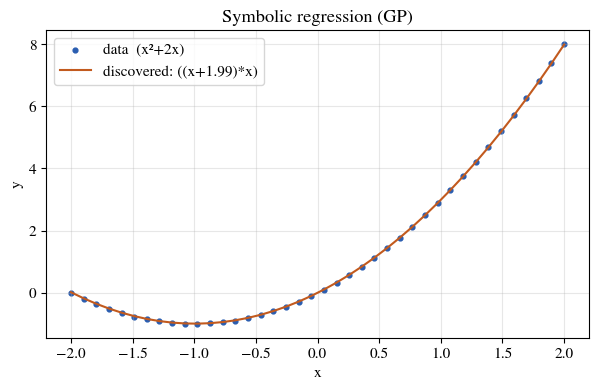

In [4]:
plt.figure(figsize=(7,4)); plt.scatter(xd,yd,s=12,label='data  (x²+2x)')
plt.plot(xd,ev(best,xd),'C1',label=f'discovered: {to_str(best)}'); plt.legend(); plt.xlabel('x'); plt.ylabel('y'); plt.title('Symbolic regression (GP)'); plt.show()

**Section 1 in one line.** GP searches expression space directly and rediscovers the law with no library, at the
cost of a stochastic combinatorial search. How large is that space? With $b$ binary operators and $L$ leaf types,
the number of distinct trees with $k$ operators is the Catalan number $C_k=\binom{2k}{k}/(k+1)$ (the tree shapes)
times $b^k$ (the operators) times $L^{k+1}$ (the leaves).

In [5]:
from math import comb
def n_trees(k, b, L): return comb(2*k, k)//(k + 1) * b**k * L**(k + 1)
for k in [1, 3, 5, 10]:
    print(f'{k:2d} operators: {n_trees(k, 4, 2):.2e} trees  (b = 4 operators, L = 2 leaf types; constants not even counted)')

 1 operators: 1.60e+01 trees  (b = 4 operators, L = 2 leaf types; constants not even counted)
 3 operators: 5.12e+03 trees  (b = 4 operators, L = 2 leaf types; constants not even counted)
 5 operators: 2.75e+06 trees  (b = 4 operators, L = 2 leaf types; constants not even counted)
10 operators: 3.61e+13 trees  (b = 4 operators, L = 2 leaf types; constants not even counted)


Ten operators already give $3.6\times10^{13}$ shapes-with-labels, before any constant is chosen. Exhaustive search
is out; the search must be guided, and every constant it does not have to *guess* is a dimension removed.

## 2. A practical GP: linear scaling, constant optimization, a Pareto archive

**Linear scaling** (Keijzer, 2003). Score a tree $g=T(\boldsymbol x)$ not by $\|g-\boldsymbol y\|^2$ but by its best
affine rescaling $a+b\,g$. Both constants have closed forms,
$$b=\frac{\mathrm{cov}(g,y)}{\mathrm{var}(g)},\qquad a=\bar y-b\,\bar g,\qquad
\min_{a,b}\tfrac1N\|a+b\,g-y\|^2=\mathrm{var}(y)\,\big(1-\rho(g,y)^2\big),$$
so the fitness depends only on the correlation $\rho$ between tree and data: the search hunts for the **shape**, and
the outer scale and offset are free. **Constant optimization.** Constants inside the tree enter nonlinearly; the ten
best trees of every generation have them refined by a few Levenberg--Marquardt steps (`scipy.optimize.least_squares`).
**Pareto archive.** The best tree of every size seen during the run is kept; the result is the accuracy--complexity
front, not a single tree. The reported model is its **knee**, chosen by the rule PySR uses: among the trees within a
factor $1.5$ of the best error, the one with the largest drop in $\ln\mathrm{NMSE}$ per added node. Fitness is the normalized error $\mathrm{NMSE}=\mathrm{MSE}/\mathrm{var}(y)$ plus
$\gamma\,\mathrm{size}$. Operators $\{+,-,\times,\div\}$ (protected division) and optional unary
$\{\sqrt{|\cdot|},|\cdot|\}$.

In [6]:
# ---- Parameters (edit these, then Run All) -------------------------------
POP_N, GENS = 500, 40            # population and generations of the benchmark runs
GAMMA = 1e-3                     # parsimony penalty per node, on the normalized error
WAKE_NOISE, DRAG_NOISE = 0.04, 0.15   # 4 % multiplicative noise on the deficit; additive noise on the drag force
N_SEEDS, ABL_POP, ABL_GENS = 10, 300, 15   # ablation: seeds and a deliberately small budget
# --------------------------------------------------------------------------
DEFAULTS = dict(POP_N=500, GENS=40, GAMMA=1e-3, WAKE_NOISE=0.04, DRAG_NOISE=0.15, N_SEEDS=10, ABL_POP=300, ABL_GENS=15)
AT_DEFAULTS = all(globals()[k] == v for k, v in DEFAULTS.items())

import time
from scipy.optimize import least_squares
from pyutils import save_dual, fg, muted
FIG = os.path.abspath(os.path.join('..', 'figures')); os.makedirs(FIG, exist_ok=True)

BIN = {'+': np.add, '-': np.subtract, '*': np.multiply,
       '/': lambda a, b: np.where(np.abs(b) > 1e-6, a/np.where(np.abs(b) > 1e-6, b, 1.0), 1.0)}
UN = {'sqrt': lambda a: np.sqrt(np.abs(a)), 'abs': np.abs}

def rnd_tree2(rng, depth=0, maxd=4, un=('sqrt',)):
    if depth >= maxd or (depth > 0 and rng.random() < 0.3):
        return ('x',) if rng.random() < 0.6 else ('c', round(rng.uniform(-3, 3), 2))
    if un and rng.random() < 0.2: return (rng.choice(un), rnd_tree2(rng, depth + 1, maxd, un))
    return (rng.choice(list(BIN)), rnd_tree2(rng, depth + 1, maxd, un), rnd_tree2(rng, depth + 1, maxd, un))
def ev2(t, x):
    k = t[0]
    if k == 'x': return x
    if k == 'c': return np.full_like(x, t[1])
    if k in UN: return UN[k](ev2(t[1], x))
    return BIN[k](ev2(t[1], x), ev2(t[2], x))
def size2(t): return 1 if t[0] in ('x', 'c') else 1 + sum(size2(s) for s in t[1:])
def str2(t):
    k = t[0]
    if k == 'x': return 'x'
    if k == 'c': return f'{t[1]:.3g}'
    if k in UN: return f'{k}({str2(t[1])})'
    return f'({str2(t[1])} {k} {str2(t[2])})'
def paths(t, p=()):
    out = [p]
    for i, s in enumerate(t[1:], 1):
        if isinstance(s, tuple): out += paths(s, p + (i,))
    return out

def scaled(t, x, y, linear=True):
    # (MSE, a, b) of the best a + b*T(x) (linear scaling), or of T(x) itself
    g = ev2(t, x)
    if not np.all(np.isfinite(g)): return np.inf, 0.0, 1.0
    if not linear: return float(np.mean((g - y)**2)), 0.0, 1.0
    vg = g.var()
    if vg < 1e-12: return float(y.var()), float(y.mean()), 0.0
    b = np.mean((g - g.mean())*(y - y.mean()))/vg; a = y.mean() - b*g.mean()
    return float(np.mean((a + b*g - y)**2)), float(a), float(b)

def with_consts(t, vals):
    for pth, v in zip([q for q in paths(t) if get(t, q)[0] == 'c'], vals): t = setn(t, pth, ('c', float(v)))
    return t
def opt_consts(t, x, y, linear):
    c0 = [get(t, q)[1] for q in paths(t) if get(t, q)[0] == 'c']
    if not c0: return t
    def res(c):
        tt = with_consts(t, c); _, a, b = scaled(tt, x, y, linear); r = a + b*ev2(tt, x) - y
        return np.where(np.isfinite(r), r, 1e3)
    try: return with_consts(t, least_squares(res, c0, max_nfev=50).x)
    except Exception: return t

def gp(x, y, seed=0, pop_n=POP_N, gens=GENS, gamma=GAMMA, linear=True, copt=True, un=('sqrt',), maxsize=40):
    # returns the Pareto archive {size: (NMSE, tree)} and the history (mean size, best fitness) per generation
    rng = random.Random(seed); vy = y.var()
    fit = lambda t: scaled(t, x, y, linear)[0]/vy + gamma*size2(t) if size2(t) <= maxsize else np.inf
    pop = [rnd_tree2(rng, un=un) for _ in range(pop_n)]; archive, hist = {}, []
    for g in range(gens):
        sc = [fit(t) for t in pop]; order = np.argsort(sc); pop = [pop[i] for i in order]
        if copt: pop[:10] = [opt_consts(t, x, y, linear) for t in pop[:10]]
        for t in pop:
            m = scaled(t, x, y, linear)[0]/vy; s = size2(t)
            if np.isfinite(m) and (s not in archive or m < archive[s][0]): archive[s] = (m, t)
        hist.append((float(np.mean([size2(t) for t in pop])), float(min(sc))))
        new = pop[:20]                                               # elitism
        while len(new) < pop_n:
            a = pop[min(rng.sample(range(pop_n), 4))]; b = pop[min(rng.sample(range(pop_n), 4))]   # tournaments
            c = setn(a, rng.choice(paths(a)), get(b, rng.choice(paths(b))))                         # crossover
            if rng.random() < 0.3: c = setn(c, rng.choice(paths(c)), rnd_tree2(rng, maxd=2, un=un)) # mutation
            new.append(c)
        pop = new
    return archive, hist

def front(archive):
    # Pareto front: sizes at which the error strictly improves on every smaller tree
    out, best = [], np.inf
    for s in sorted(archive):
        m, t = archive[s]
        if m < best*0.999: out.append((s, m, t)); best = m
    return out

def knee(fr, within=1.5):
    # PySR's rule: among front entries with error <= within * best, the largest drop of log-error per added node
    best = min(m for _, m, _ in fr)
    score = [0.0] + [np.log(fr[i - 1][1]/fr[i][1])/(fr[i][0] - fr[i - 1][0]) for i in range(1, len(fr))]
    ok = [i for i in range(len(fr)) if fr[i][1] <= within*best]
    return fr[max(ok, key=lambda i: score[i])]

def show_front(fr, x, y, linear=True, upto=8):
    for s, m, t in fr[:upto]:
        _, a, b = scaled(t, x, y, linear); print(f'   size {s:2d}  NMSE {m:.5f}   {a:+.3f} {b:+.3f} * {str2(t)}')

## 3. The wake decay law, with no library

The data of `ed_sindy_wind.ipynb`: the far-wake centreline deficit $d(x)=x^{-1/2}/\sqrt{4\pi D}$ with $D=\nu_t/U=0.0625$
(amplitude $1.128$), $60$ samples on $x\in[1,8]$, $4\%$ multiplicative noise. SINDy needed the power-law library
$\{x^0,x^{-1/2},\dots\}$, i.e. it needed to be told the answer was a power. Here the operators are only
$\{+,-,\times,\div,\sqrt{\cdot}\}$.

In [7]:
rs = np.random.default_rng(0)
xw = np.linspace(1.0, 8.0, 60); amp = 1/np.sqrt(4*np.pi*0.0625)
yw = amp/np.sqrt(xw)*(1 + WAKE_NOISE*rs.standard_normal(60))
t0 = time.perf_counter(); ar_w, hist_w = gp(xw, yw, un=('sqrt',)); T_W = time.perf_counter() - t0
fr_w = front(ar_w); kw = knee(fr_w)
print(f'wake: {GENS} generations of {POP_N} trees in {T_W:.1f} s; Pareto front:'); show_front(fr_w, xw, yw)
_, a_w, b_w = scaled(kw[2], xw, yw)
amp_hat = float(b_w*ev2(kw[2], np.array([1.0]))[0])           # value of b*T at x = 1: the amplitude if T ~ x^-1/2
print(f'knee: size {kw[0]}, {a_w:+.3f} {b_w:+.3f} * {str2(kw[2])}  ->  amplitude {amp_hat:.3f} (derived {amp:.3f}), '
      f'offset {a_w:+.3f}')
NMSE_TRUE_W = float(np.mean((amp/np.sqrt(xw) - yw)**2)/yw.var())
print(f'the exact law itself scores NMSE = {NMSE_TRUE_W:.4f} on these noisy data (the noise floor)')
if AT_DEFAULTS:
    assert kw[0] == 4 and abs(amp_hat - amp)/amp < 0.03 and abs(a_w) < 0.02

wake: 40 generations of 500 trees in 1.0 s; Pareto front:
   size  1  NMSE 0.17374   +0.954 -0.080 * x
   size  2  NMSE 0.09804   +1.277 -0.332 * sqrt(x)
   size  3  NMSE 0.02568   +0.326 -0.298 * (-2.97 / x)
   size  4  NMSE 0.01302   +0.007 -0.657 * (-1.7 / sqrt(x))
   size  5  NMSE 0.01282   +2.506 -2.261 * (x / (x + 0.645))
   size  6  NMSE 0.01236   +0.058 +0.379 * (2.49 / (-0.13 + sqrt(x)))
   size 12  NMSE 0.01232   -0.044 +0.942 * (sqrt(sqrt(((x + sqrt(-2.3)) / sqrt(x)))) / sqrt(x))
   size 13  NMSE 0.01231   -0.021 -2.569 * (sqrt((x - (-2.23 - -0.86))) / ((sqrt(x) + x) * -1.7))
knee: size 4, +0.007 -0.657 * (-1.7 / sqrt(x))  ->  amplitude 1.117 (derived 1.128), offset +0.007
the exact law itself scores NMSE = 0.0132 on these noisy data (the noise floor)


**Picture of linear scaling.** Two raw trees, $g=1/\sqrt{x}$ and $g=1/x$, against the wake data. Unscaled, both
are far off. After the closed-form rescaling $a+b\,g$ the right *shape* fits to the noise floor, while the wrong shape
cannot be rescued: the scaled error is $\mathrm{var}(y)(1-\rho^2)$, fixed by the correlation alone.

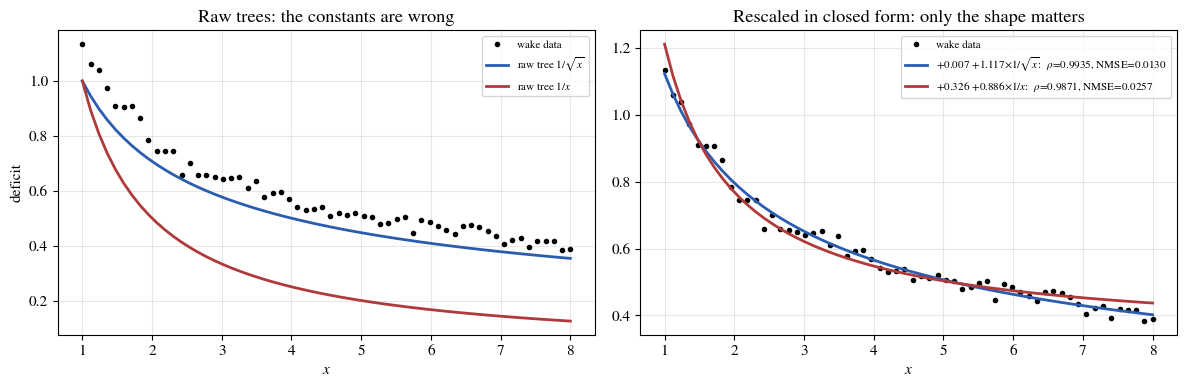

In [8]:
def plot_linscale():
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.0))
    shapes = [('$1/\\sqrt{x}$', 1/np.sqrt(xw), 'C0'), ('$1/x$', 1/xw, 'C3')]
    for a in ax: a.plot(xw, yw, 'o', color=fg(), ms=3, label='wake data')
    for lab, g, col in shapes:
        ax[0].plot(xw, g, color=col, lw=2, label=f'raw tree {lab}')
        b_ = np.cov(g, yw, bias=True)[0, 1]/g.var(); a_ = yw.mean() - b_*g.mean()
        rho = np.corrcoef(g, yw)[0, 1]
        ax[1].plot(xw, a_ + b_*g, color=col, lw=2, label=f'{a_:+.3f} {b_:+.3f}$\\times${lab}:  $\\rho$={rho:.4f}, NMSE={1 - rho**2:.4f}')
    ax[0].set(xlabel='$x$', ylabel='deficit', title='Raw trees: the constants are wrong'); ax[0].legend(fontsize=8)
    ax[1].set(xlabel='$x$', title='Rescaled in closed form: only the shape matters'); ax[1].legend(fontsize=8)
    plt.tight_layout()
save_dual(plot_linscale, 'ed_sr_linscale', FIG)
plt.show()

The front drops steeply to size $4$ and is flat after it: $x$ (size 1), $\sqrt x$ (2), $1/x$ (3), then
$c/\sqrt x$ (4), after which ten more nodes buy the last few percent of a noise floor. The knee is the derived law,
amplitude within about one percent and an offset of a few thousandths. The noise floor is visible in the numbers: the
exact law scores $\mathrm{NMSE}=0.0132$ on these noisy data, the knee scores $0.0130$, and every larger tree below it is
fitting the noise.

## 4. Closing the loop without a library: the vessel drag correction

The learned drag correction of the vessel notebook, in surge: $f(u)=-3\,u|u|$ sampled over the visited speeds
$u\in[-0.8,3.9]$, with additive noise. The vessel notebook recovered it with a library that already contained $|u|u$.
Here the unary operators are $\{|\cdot|,\sqrt{|\cdot|}\}$ and nothing else is assumed.

In [9]:
ud = np.linspace(-0.8, 3.9, 80); yd_ = -3*np.abs(ud)*ud + DRAG_NOISE*rs.standard_normal(80)
t0 = time.perf_counter(); ar_d, hist_d = gp(ud, yd_, un=('abs', 'sqrt')); T_D = time.perf_counter() - t0
fr_d = front(ar_d); kd = knee(fr_d)
print(f'drag: {T_D:.1f} s; Pareto front:'); show_front(fr_d, ud, yd_, upto=6)
_, a_d, b_d = scaled(kd[2], ud, yd_)
print(f'knee: size {kd[0]}, {a_d:+.3f} {b_d:+.3f} * {str2(kd[2])}')
if AT_DEFAULTS:
    assert kd[0] == 4 and abs(b_d + 3) < 0.05

drag: 0.7 s; Pareto front:
   size  1  NMSE 0.11187   +2.227 -9.579 * x
   size  2  NMSE 0.06235   +6.622 -11.355 * abs(x)
   size  3  NMSE 0.00265   +0.439 -3.044 * (x * x)
   size  4  NMSE 0.00012   +0.009 -3.000 * (x * abs(x))
   size  8  NMSE 0.00012   +0.066 -2.978 * (abs(((-0.05 * 0.59) - x)) * x)
knee: size 4, +0.009 -3.000 * (x * abs(x))


The knee is $-3.00\,x|x|$ at size $4$; one node smaller, $-3.04\,x^2$ is close because $u$ is mostly positive
(the aliasing of `ed_failure_modes.ipynb` again), but its error is twenty times larger, because the negative speeds in
the data tell $x|x|$ from $x^2$. Symbolic regression and the incomplete-library failure meet here: SR *can* find the term
a library forgot, provided the data visits the states that distinguish it.

## 5. What each ingredient buys, and what the parsimony penalty prevents

Success = the front contains the true law at its knee size ($c/\sqrt{x}$, or $c\,x|x|$) with error at the noise floor.
Ten seeds, a deliberately small budget ($300$ trees, $15$ generations). Without linear scaling the tree must carry the
outer constant itself, so it is allowed one more node.

In [10]:
def success(x, y, un, tgt, size_lin, **cfg):
    lim = size_lin + (0 if cfg.get('linear', True) else 1)
    return sum(any(s <= lim and m <= tgt for s, m, _ in front(gp(x, y, seed=sd, pop_n=ABL_POP, gens=ABL_GENS, un=un, **cfg)[0]))
               for sd in range(N_SEEDS))
configs = [('linear scaling + constant opt.', dict()), ('constant opt. only', dict(linear=False)),
           ('neither', dict(linear=False, copt=False))]
tg_w, tg_d = 1.05*kw[1], 1.5*kd[1]                     # 'at the noise floor': near the knee error of the full run
abl = {name: (success(xw, yw, ('sqrt',), tg_w, 4, **cfg), success(ud, yd_, ('abs', 'sqrt'), tg_d, 4, **cfg)) for name, cfg in configs}
print(f'{"":32s} {"wake":>6} {"drag":>6}   (successes out of {N_SEEDS} seeds)')
for name, (sw, sd_) in abl.items(): print(f'{name:32s} {sw:6d} {sd_:6d}')

_, hist_bloat = gp(xw, yw, gamma=0.0, un=('sqrt',))
print(f'mean tree size after {GENS} generations: parsimony gamma = {GAMMA:g}: {hist_w[-1][0]:.1f};  gamma = 0: {hist_bloat[-1][0]:.1f}')
if AT_DEFAULTS:
    assert abl[configs[0][0]][0] >= 8 and abl[configs[0][0]][1] >= 8 and hist_bloat[-1][0] > 2*hist_w[-1][0]

                                   wake   drag   (successes out of 10 seeds)
linear scaling + constant opt.       10     10
constant opt. only                    8      0
neither                               4      0


mean tree size after 40 generations: parsimony gamma = 0.001: 7.8;  gamma = 0: 31.7


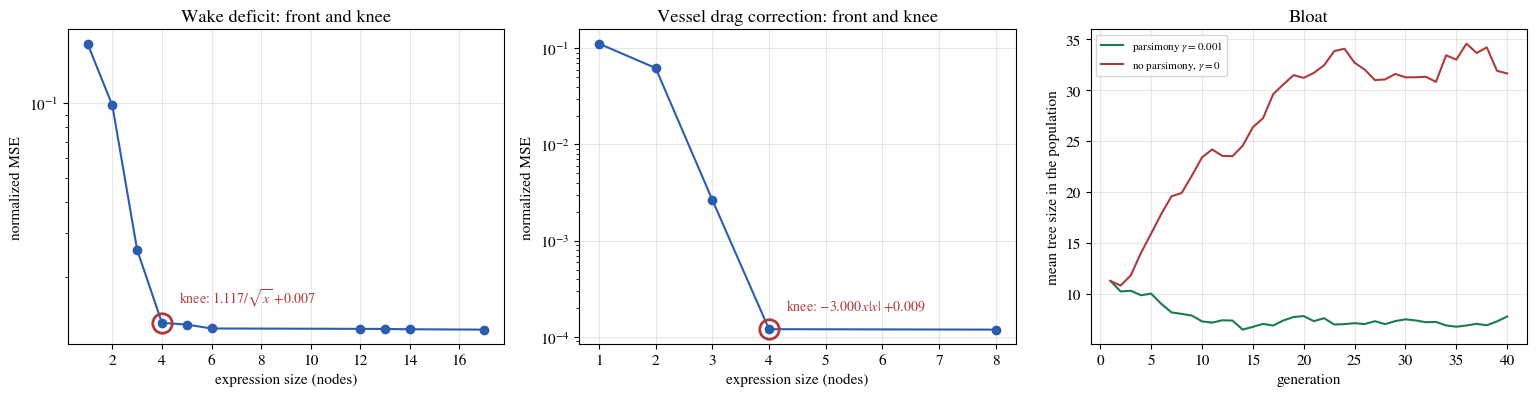

In [11]:
def plot_sr():
    fig, ax = plt.subplots(1, 3, figsize=(15.5, 4.1))
    lab_w = f'knee: ${amp_hat:.3f}/\\sqrt{{x}}$' + (f' ${a_w:+.3f}$' if abs(a_w) >= 5e-4 else '')
    lab_d = f'knee: ${b_d:.3f}\\,x|x|$' + (f' ${a_d:+.3f}$' if abs(a_d) >= 5e-4 else '')
    for a, fr, k, ttl, lab in [(ax[0], fr_w, kw, 'Wake deficit: front and knee', lab_w),
                               (ax[1], fr_d, kd, 'Vessel drag correction: front and knee', lab_d)]:
        s = [e[0] for e in fr]; m = [e[1] for e in fr]
        a.semilogy(s, m, 'o-', color='C0'); a.semilogy([k[0]], [k[1]], 'o', ms=14, mfc='none', mec='C3', mew=2)
        a.annotate(lab, (k[0], k[1]), textcoords='offset points', xytext=(12, 14), color='C3', fontsize=10)
        a.set(xlabel='expression size (nodes)', ylabel='normalized MSE', title=ttl)
    g = np.arange(1, GENS + 1)
    ax[2].plot(g, [h[0] for h in hist_w], color='C2', label=f'parsimony $\\gamma={GAMMA:g}$')
    ax[2].plot(g, [h[0] for h in hist_bloat], color='C3', label='no parsimony, $\\gamma=0$')
    ax[2].set(xlabel='generation', ylabel='mean tree size in the population', title='Bloat')
    ax[2].legend(fontsize=8); plt.tight_layout()

save_dual(plot_sr, 'ed_sr_benchmarks', FIG)
plt.show()

In [12]:
# the two fronts as separate figures (lecture slides), each annotated with every tree on the front
NMSE_TRUE_D = float(np.mean((-3*np.abs(ud)*ud - yd_)**2)/yd_.var())
def front_fig(fr, k, x, y, floor, name, ttl):
    def f():
        fig, a = plt.subplots(figsize=(6.4, 4.0))
        s_ = [e[0] for e in fr]; m_ = [e[1] for e in fr]
        a.semilogy(s_, m_, 'o-', color='C0', label='best tree found at each size')
        a.axhline(floor, color='C3', ls='--', lw=1, label=f'the exact law on these data (noise floor) = {floor:.4f}')
        a.semilogy([k[0]], [k[1]], 'o', ms=15, mfc='none', mec='C2', mew=2.2, label='knee = reported model')
        for sz, m, t in fr:
            if sz <= k[0]:
                a.annotate(f'{str2(t)}', (sz, m), textcoords='offset points', xytext=(7, 5), fontsize=7, color=fg())
        tail = [e for e in fr if e[0] > k[0]]
        if tail:
            a.annotate('larger trees: only fitting the noise', (tail[-1][0], tail[-1][1]), textcoords='offset points',
                       xytext=(-150, 22), fontsize=7, color=fg(), arrowprops=dict(arrowstyle='->', color=muted()))
        a.set(xlabel='expression size (nodes)', ylabel='NMSE  (0 = perfect, 1 = predicts the mean)', title=ttl)
        a.legend(fontsize=7, loc='upper right'); plt.tight_layout()
    save_dual(f, name, FIG); plt.close('all')
front_fig(fr_w, kw, xw, yw, NMSE_TRUE_W, 'ed_sr_front_wake', 'Wake deficit: the accuracy-size front')
front_fig(fr_d, kd, ud, yd_, NMSE_TRUE_D, 'ed_sr_front_drag', 'Vessel drag correction: the front')
print(f'noise floors: wake {NMSE_TRUE_W:.4f}, drag {NMSE_TRUE_D:.5f}')

noise floors: wake 0.0132, drag 0.00012


With linear scaling and constant optimization both laws are found on every seed. Constant optimization alone finds the
wake law on eight seeds in ten (it can be written $\sqrt{c/x}$, with the constant inside the tree); without either, four
seeds in ten. The drag law is never found without linear scaling: the tree would have to carry the factor $-3$ as an
explicit multiplication, one more node and a constant at the edge of the random range, and on this budget the search
never assembles it. Linear scaling removes exactly that burden. Without the parsimony penalty the population **bloats**: trees grow
to several times the size, mostly in subtrees that do not change the output (introns), which slows every evaluation and
hides the simple law inside a large expression.

## 6. Snapping: how neural-symbolic methods name a learned function

A Kolmogorov--Arnold network (KAN) learns a univariate function on each edge; EQL learns a sparse combination of
primitive units. Either way the last step is the same: **snap** a learned univariate curve $\phi(x)$ to the primitive
$g$ that best fits $a\,g(b\,x+c)+d$, and replace the curve by the formula. The cell below does that step on the learned drag
correction (the curve a KAN edge would hold), fitting the four constants for every candidate by least squares from a few
starts and ranking by $R^2$. (The fit of each candidate is a small nonlinear least-squares problem; with four free constants
several primitives can come close, which is why the ranking, not the winner alone, is reported.)

In [13]:
PRIM = {'x': lambda z: z, 'x^2': lambda z: z**2, 'x^3': lambda z: z**3, 'x|x|': lambda z: z*np.abs(z),
        'sqrt|x|': lambda z: np.sqrt(np.abs(z)), 'exp': lambda z: np.exp(np.clip(z, -30, 30)), 'sin': np.sin,
        'tanh': np.tanh}
def snap(x, y, starts=8, seed=0):
    rng = np.random.default_rng(seed); out = {}
    for nm, g in PRIM.items():
        best = None
        for _ in range(starts):
            p0 = [rng.normal(), rng.uniform(0.3, 2), rng.normal(0, 0.3), rng.normal()]
            try:
                r = least_squares(lambda q: q[0]*g(q[1]*x + q[2]) + q[3] - y, p0, max_nfev=400)
                if best is None or r.cost < best.cost: best = r
            except Exception: pass
        out[nm] = (1 - 2*best.cost/np.sum((y - y.mean())**2), best.x)
    return sorted(out.items(), key=lambda kv: -kv[1][0])
ranked = snap(ud, yd_)
for nm, (r2_, q) in ranked[:5]:
    print(f'{nm:8s} R^2 = {r2_:.5f}   a = {q[0]:+.3f}, b = {q[1]:+.3f}, c = {q[2]:+.3f}, d = {q[3]:+.3f}')
a_, b_, c_, d_ = ranked[0][1][1]
print(f'snapped: {ranked[0][0]} with effective coefficient a*b^2 = {a_*b_**2:+.3f} and shift c/b = {c_/b_:+.3f}')
if AT_DEFAULTS:
    assert ranked[0][0] == 'x|x|'

x|x|     R^2 = 0.99988   a = -0.572, b = +2.285, c = +0.023, d = +0.048
tanh     R^2 = 0.99944   a = -40.455, b = +0.499, c = -1.768, d = -37.898
x^3      R^2 = 0.99909   a = +0.832, b = -0.699, c = -1.138, d = +1.634
x^2      R^2 = 0.99879   a = -0.770, b = +1.891, c = +0.360, d = +0.909
sin      R^2 = 0.99877   a = +2533.901, b = -0.047, c = +1.562, d = -2532.991
snapped: x|x| with effective coefficient a*b^2 = -2.985 and shift c/b = +0.010


**Picture of the snapping step.** The noisy samples of the learned drag correction, the four best-ranked
primitives after fitting $a\,g(bx+c)+d$, and what each does *outside* the sampled speeds. Inside the data the curves are
indistinguishable; outside, only $x|x|$ behaves like a drag force.

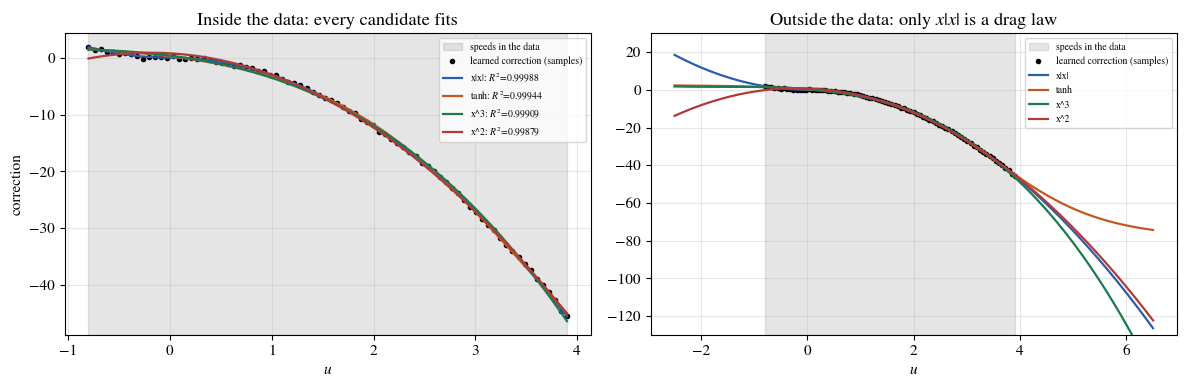

In [14]:
xx_ext = np.linspace(-2.5, 6.5, 300)
def plot_snapping():
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.0))
    for a in ax:
        a.axvspan(ud.min(), ud.max(), color=muted(), alpha=0.15, label='speeds in the data')
        a.plot(ud, yd_, 'o', color=fg(), ms=3, label='learned correction (samples)')
    for k, (nm, (r2_, q)) in enumerate(ranked[:4]):
        g = PRIM[nm]; col = f'C{k}'
        ax[0].plot(ud, q[0]*g(q[1]*ud + q[2]) + q[3], color=col, lw=1.6, label=f'{nm}: $R^2$={r2_:.5f}')
        ax[1].plot(xx_ext, q[0]*g(q[1]*xx_ext + q[2]) + q[3], color=col, lw=1.6, label=nm)
    ax[0].set(xlabel='$u$', ylabel='correction', title='Inside the data: every candidate fits'); ax[0].legend(fontsize=7)
    ax[1].set(xlabel='$u$', ylim=(-130, 30), title='Outside the data: only $x|x|$ is a drag law'); ax[1].legend(fontsize=7)
    plt.tight_layout()
save_dual(plot_snapping, 'ed_snapping', FIG)
plt.show()

The winner is $x|x|$ with effective coefficient $-2.99$, but $\tanh$ (with $a=-40$ and an offset of $-38$) and $x^3$
reach $R^2>0.999$ too: four free constants make many primitives fit a smooth curve on a finite range. Snapping therefore
needs the same discipline as symbolic regression --- prefer the candidate whose constants are of order one and that
extrapolates sensibly --- and it is only as good as the range the curve was learned on.

**Takeaways.** Symbolic regression rediscovers both benchmark laws from data with no library, and returns them as the
knee of an accuracy--complexity front rather than as a single answer. Three engineering choices make the difference
between a toy and a tool: linear scaling (the search looks for shapes; the outer constants are solved in closed form),
constant optimization (the inner constants are fitted, not guessed) and parsimony pressure (against bloat). Snapping is
the same idea in one dimension and is how KAN and EQL turn a trained network into a formula. Use SINDy when the terms
are guessable; reach for symbolic regression when the form is unknown, and make sure the data visits the states that
tell competing forms apart.